**Project: Book Recommendation System**

The Book Recommendation System suggests books to users based on book details and user ratings.
It uses content-based filtering and collaborative filtering techniques to identify books that users may enjoy.
The system evaluates its recommendations and provides personalized book suggestions to improve the user experience.

**Install and upload datasets**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

books = pd.read_csv("books.csv")
ratings = pd.read_csv("ratings.csv")

print("Books dataset shape:", books.shape)
print("Ratings dataset shape:", ratings.shape)

display(books.head())
display(ratings.head())

Saving books.csv to books.csv
Saving ratings.csv to ratings.csv
Books dataset shape: (10000, 23)
Ratings dataset shape: (5976479, 3)


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


**Clean data, and EDA**

Users: 10000
Books: 9955
Ratings: 1117979
Sparsity: 98.88 %


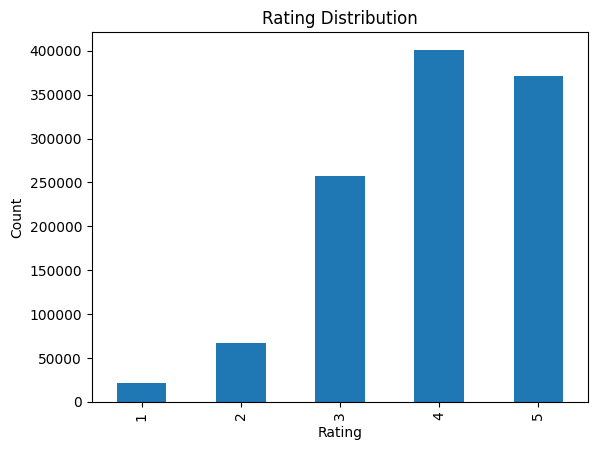

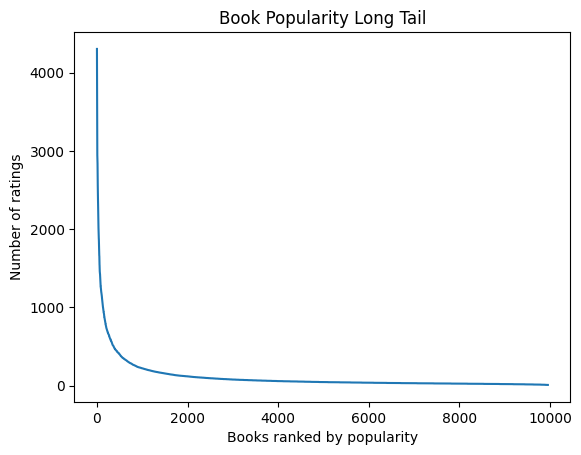

In [2]:
ratings = ratings.dropna(
    subset=["user_id", "book_id", "rating"]
).drop_duplicates(["user_id", "book_id"])

ratings = ratings[ratings["rating"].between(1, 5)].copy()
ratings = ratings[ratings["book_id"].isin(books["book_id"])]

counts = ratings.groupby("user_id").size()
active = counts[counts >= 20].index

rng = np.random.default_rng(42)
chosen = rng.choice(active, min(10000, len(active)), replace=False)
ratings = ratings[ratings["user_id"].isin(chosen)].copy()

item_counts = ratings.groupby("book_id").size()
ratings = ratings[ratings["book_id"].isin(
    item_counts[item_counts >= 10].index
)].copy()

books = books[books["book_id"].isin(ratings["book_id"].unique())].copy()

print("Users:", ratings.user_id.nunique())
print("Books:", ratings.book_id.nunique())
print("Ratings:", len(ratings))
print("Sparsity:", round(
    (1 - len(ratings) /
     (ratings.user_id.nunique() * ratings.book_id.nunique())) * 100, 2
), "%")

ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

ratings.groupby("book_id").size().sort_values(
    ascending=False
).reset_index(drop=True).plot()
plt.title("Book Popularity Long Tail")
plt.xlabel("Books ranked by popularity")
plt.ylabel("Number of ratings")
plt.show()

**Train/test split and baselines**

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

train, test = train_test_split(
    ratings, test_size=0.2, random_state=42
)

test = test[
    test.user_id.isin(train.user_id) &
    test.book_id.isin(train.book_id)
].copy()

global_mean = train.rating.mean()
user_mean = train.groupby("user_id").rating.mean()
item_mean = train.groupby("book_id").rating.mean()

print("Train:", len(train), "Test:", len(test))
print("Global mean:", round(global_mean, 3))

def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

def clip(x):
    return np.clip(x, 1, 5)

results = []

def add_result(name, predictions):
    results.append({
        "Model": name,
        "RMSE": rmse(test.rating, clip(predictions))
    })

add_result("Global Mean",
           np.full(len(test), global_mean))

add_result("User Mean",
           test.user_id.map(user_mean).fillna(global_mean))

add_result("Item Mean",
           test.book_id.map(item_mean).fillna(global_mean))

Train: 894383 Test: 223596
Global mean: 3.925


**Collaborative filtering and SVD**

In [4]:
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import TruncatedSVD

users = np.sort(train.user_id.unique())
items = np.sort(train.book_id.unique())

ui = {u: i for i, u in enumerate(users)}
ii = {b: i for i, b in enumerate(items)}

R = csr_matrix(
    (train.rating.astype(float),
     (train.user_id.map(ui), train.book_id.map(ii))),
    shape=(len(users), len(items))
)

means = np.asarray(R.sum(axis=1)).ravel() / np.maximum(
    np.diff(R.indptr), 1
)

Rc = R.copy().astype(float)
for u in range(Rc.shape[0]):
    Rc.data[Rc.indptr[u]:Rc.indptr[u+1]] -= means[u]

knn = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=21)
knn.fit(Rc.T)

def predict_cf(user, book, k=20):
    u, b = ui[user], ii[book]
    distances, neighbors = knn.kneighbors(Rc.T[b], n_neighbors=k+1)
    row = Rc.getrow(u)
    numerator = denominator = 0.0

    for d, j in zip(distances[0], neighbors[0]):
        if j == b or row[0, j] == 0:
            continue
        s = max(0, 1-d)
        numerator += s * row[0, j]
        denominator += s

    return means[u] + numerator / denominator if denominator else means[u]

test_eval = test.head(1000)
cf_pred = [
    predict_cf(u, b)
    for u, b in zip(test_eval.user_id, test_eval.book_id)
]
print("Item-CF RMSE on 1,000 test ratings:",
      round(rmse(test_eval.rating, clip(cf_pred)), 4))

svd = TruncatedSVD(
    n_components=min(30, min(R.shape)-1),
    random_state=42
)
U = svd.fit_transform(R)
V = svd.components_.T

svd_pred = np.array([
    U[ui[u]] @ V[ii[b]]
    for u, b in zip(test.user_id, test.book_id)
])

add_result("SVD", svd_pred)

print("Evaluation results:")
display(pd.DataFrame(results).sort_values("RMSE"))

Item-CF RMSE on 1,000 test ratings: 0.8866
Evaluation results:


,Model,RMSE
1,User Mean,0.886912
2,Item Mean,0.950417
0,Global Mean,0.984225
3,SVD,2.936436


**Ranking metrics and popularity bias**

In [5]:
from collections import defaultdict

seen = train.groupby("user_id").book_id.apply(set).to_dict()
relevant = defaultdict(set)

for row in test.itertuples():
    if row.rating >= 4:
        relevant[row.user_id].add(row.book_id)

popularity = train.book_id.value_counts()
all_items = list(items)

def top_recommendations(user, k=10):
    scores = V @ U[ui[user]]
    for b in seen.get(user, set()):
        if b in ii:
            scores[ii[b]] = -np.inf
    return [items[i] for i in np.argsort(scores)[::-1][:k]]

P, Rec, N = [], [], []
recommended = set()

for u in list(relevant)[:200]:
    if u not in ui or not relevant[u]:
        continue

    recs = top_recommendations(u)
    recommended.update(recs)
    hits = len(set(recs) & relevant[u])

    P.append(hits / 10)
    Rec.append(hits / len(relevant[u]))

    dcg = sum(
        1 / np.log2(rank+1)
        for rank, b in enumerate(recs, start=1)
        if b in relevant[u]
    )
    ideal = sum(
        1 / np.log2(rank+1)
        for rank in range(1, min(10, len(relevant[u]))+1)
    )
    N.append(dcg / ideal if ideal else 0)

print("Precision@10:", np.mean(P))
print("Recall@10:", np.mean(Rec))
print("NDCG@10:", np.mean(N))
print("Catalogue coverage:", len(recommended) / len(items))

top100 = set(popularity.head(100).index)
print("Top-100 popularity share:",
      sum(b in top100 for b in recommended) / max(1, len(recommended)))

Precision@10: 0.226
Recall@10: 0.12612992186439898
NDCG@10: 0.2680545183375549
Catalogue coverage: 0.036263184329482674
Top-100 popularity share: 0.27146814404432135


**Final recommendation demo**

In [6]:
def recommend(user_id, n=10):
    if user_id not in ui:
        print("New user: showing popular books.")
        rec_ids = popularity.head(n).index.tolist()
    else:
        rec_ids = top_recommendations(user_id, n)

    output = books[books.book_id.isin(rec_ids)].copy()
    output["_order"] = output.book_id.map(
        {b: i for i, b in enumerate(rec_ids)}
    )
    return output.sort_values("_order")[
        ["title", "authors", "average_rating"]
    ]

demo_user = int(train.user_id.iloc[0])
display(recommend(demo_user, 10))

,title,authors,average_rating
50,"City of Bones (The Mortal Instruments, #1)",Cassandra Clare,4.12
2,"Twilight (Twilight, #1)",Stephenie Meyer,3.57
133,"City of Glass (The Mortal Instruments, #3)",Cassandra Clare,4.34
209,"Vampire Academy (Vampire Academy, #1)",Richelle Mead,4.14
152,"City of Ashes (The Mortal Instruments, #2)",Cassandra Clare,4.21
417,"Spirit Bound (Vampire Academy, #5)",Richelle Mead,4.37
383,"Frostbite (Vampire Academy, #2)",Richelle Mead,4.30
182,"Clockwork Angel (The Infernal Devices, #1)",Cassandra Clare,4.33
418,"Blood Promise (Vampire Academy, #4)",Richelle Mead,4.35
393,"Shadow Kiss (Vampire Academy, #3)",Richelle Mead,4.37


**Required manual check and leakage experiment**

In [7]:

example = test_eval.iloc[0]
print("User:", example.user_id, "Book:", example.book_id)
print("Actual rating:", example.rating)
print("Predicted rating:", predict_cf(example.user_id, example.book_id))

honest = test.user_id.map(user_mean).fillna(global_mean)
full_mean = ratings.groupby("user_id").rating.mean()
leaky = test.user_id.map(full_mean).fillna(global_mean)

display(pd.DataFrame({
    "Experiment": ["Honest", "Leaky (invalid)"],
    "RMSE": [
        rmse(test.rating, clip(honest)),
        rmse(test.rating, clip(leaky))
    ]
}))

User: 24240 Book: 893
Actual rating: 5
Predicted rating: 4.0


,Experiment,RMSE
0,Honest,0.886912
1,Leaky (invalid),0.877977
